# Experiment: GRIP++-style (graph-based interaction)

Re-implementation of the idea of GRIP++ (Li et al., 2019): vehicles are graph nodes, edges link vehicles closer than a radius (fixed graph) and a trainable edge-importance matrix re-weights them (GRIP++'s extra graph); graph-convolution blocks mix information across nodes and time, and three seq2seq GRU decoders, averaged, predict the target's future displacements. Code was not confirmed, so layer details are ours. No NGSIM number for GRIP++ in STRAP's table; the GRIP++ paper reports results on NGSIM and ApolloScape.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | Written from the paper's description; layer sizes are ours (64 channels, 3 graph blocks, 2-layer GRUs of 64). | GRIP++ code was not checked (MODEL_ALTERNATIVES.md). | Exact GRIP++ depth (it stacks more graph blocks) is unverified. |
| M2 | Fixed graph: edge between two real vehicles closer than 15 m at the last history step, plus self-loops, column-normalised. | Distance-based adjacency as in GRIP; positions denormalized from features 0-1. | ASSUMPTION: the 15 m radius is ours; GRIP's own threshold was not verified. One graph for the whole history, not per step. |
| M3 | Trainable graph: a learnable 16 x 16 edge-importance matrix per block multiplies the fixed graph. | GRIP++ adds a trainable graph to the fixed one. | Node order is by risk rank, so learned weights mean 'k-th riskiest neighbour'. |
| M4 | Graph block = 1x1 conv, graph aggregation, BatchNorm-ReLU-temporal conv (kernel 3), residual. | GRIP-style block. | - |
| M5 | 3 seq2seq GRUs (encoder over the target node's 30 steps, autoregressive decoder for 50 steps), outputs averaged. | GRIP++ averages three seq2seq predictors. | Only the target node is decoded (our task); GRIP++ predicts every node. |
| M6 | Decoder predicts per-step displacements, cumulative-summed to positions; plus a softplus sigma and tanh rho head. | Displacements as in GRIP; sigma needed for our NLL term. | GRIP++ trains with MSE only and has no uncertainty. |
| M7 | Kept 10 Hz (50 output steps). | Same evaluation grid as every model. | GRIP++ downsamples to 5 Hz. |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "grip_pp"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "GRIP++-style: distance graph + trainable graph, graph conv blocks, 3 averaged seq2seq GRUs"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-29 15:16:06,130 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-29 15:16:13,823 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-29 15:16:14,633 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-29 15:16:14,658 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-29 15:16:14,686 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-29 15:34:01,378 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-29 15:34:31,246 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/grip_pp/intention_clusters.pkl


2026-10-29 15:34:32,812 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** paper-description re-implementation (M1); 15 m distance graph from denormalized positions (M2, assumption); trainable edge importance (M3); GRIP-style blocks (M4); 3 averaged seq2seq GRUs on the target node (M5); displacement + sigma head (M6); 10 Hz (M7). Built after the data cell because it needs `norm_stats`.

In [4]:
class GraphBlock(nn.Module):
    """1x1 conv -> graph aggregation (fixed x trainable graph) -> temporal conv, with a residual (M3, M4)."""
    def __init__(self, c_in, c_out, n_nodes, k_t=3, dropout=DROPOUT):
        super().__init__()
        self.spatial = nn.Conv2d(c_in, c_out, 1)
        self.temporal = nn.Sequential(
            nn.BatchNorm2d(c_out), nn.ReLU(),
            nn.Conv2d(c_out, c_out, (k_t, 1), padding=(k_t // 2, 0)),
            nn.BatchNorm2d(c_out), nn.Dropout(dropout))
        self.residual = nn.Identity() if c_in == c_out else nn.Conv2d(c_in, c_out, 1)
        self.edge_importance = nn.Parameter(torch.ones(n_nodes, n_nodes))   # M3: trainable graph

    def forward(self, x, A):                                        # x (B, C, T, N), A (B, N, N)
        N = A.shape[-1]
        y = torch.einsum("bctn,bnm->bctm", self.spatial(x), A * self.edge_importance[:N, :N])
        return F.relu(self.temporal(y) + self.residual(x))


class Seq2Seq(nn.Module):
    """GRU encoder over the target node's history, autoregressive GRU decoder (M5, M6)."""
    def __init__(self, c, hidden=64, T_f=TF_STEPS):
        super().__init__()
        self.T_f = T_f
        self.encoder = nn.GRU(c, hidden, num_layers=2, batch_first=True)
        self.decoder = nn.GRU(2, hidden, num_layers=2, batch_first=True)
        self.out = nn.Linear(hidden, 5)                             # dx, dy, raw sigma x/y, raw rho

    def forward(self, seq):                                         # (B, T_h, c)
        _, h = self.encoder(seq)
        step, outs = seq.new_zeros(seq.shape[0], 1, 2), []
        for _ in range(self.T_f):
            o, h = self.decoder(step, h)
            o = self.out(o)
            outs.append(o)
            step = o[..., :2]                                       # feed the predicted displacement back
        return torch.cat(outs, dim=1)                               # (B, T_f, 5)


class GRIPpp(nn.Module):
    def __init__(self, norm_stats, input_dim=STATE_DIM, c=64, radius=15.0, n_blocks=3, n_seq2seq=3):
        super().__init__()
        self.radius = radius                                        # M2: assumption
        self.register_buffer("mean", torch.tensor(norm_stats["mean"]))
        self.register_buffer("std", torch.tensor(norm_stats["std"]))
        n_nodes = N_V + 1
        self.blocks = nn.ModuleList(
            [GraphBlock(input_dim if i == 0 else c, c, n_nodes) for i in range(n_blocks)])
        self.seq2seq = nn.ModuleList([Seq2Seq(c) for _ in range(n_seq2seq)])

    def graph(self, states, mask):
        """Fixed graph (M2): real vehicles closer than `radius` at the last step + self-loops."""
        N = states.shape[2]
        pos = states[:, -1, :, :2] * self.std[:2] + self.mean[:2]  # metres relative to the target
        near = (torch.cdist(pos, pos) < self.radius) & mask[:, :, None] & mask[:, None, :]
        A = near.float() + torch.eye(N, device=states.device)
        return A / A.sum(dim=1, keepdim=True)                       # column-normalised: weights into node m sum to 1

    def forward(self, states, mask, dims=None):
        B, T_h, N, _ = states.shape
        A = self.graph(states, mask)
        x = states.permute(0, 3, 1, 2)                              # (B, F, T, N)
        for block in self.blocks:
            x = block(x, A)
        target_seq = x[..., 0].transpose(1, 2)                      # (B, T_h, c) target node
        raw = torch.stack([s(target_seq) for s in self.seq2seq]).mean(0)   # M5: average of 3 heads
        mu = raw[..., :2].cumsum(dim=1)                             # M6: displacements -> positions
        traj = torch.cat([mu, F.softplus(raw[..., 2:4]) + 1e-3, torch.tanh(raw[..., 4:])], dim=-1)
        return traj, states.new_zeros(B, N - 1, 4), None


def build_model():
    return GRIPpp(norm_stats)

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

GRIPpp: 313,231 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-29 15:34:33,654 - STRAP - INFO - Training STRAP on cuda


2026-10-29 15:34:33,655 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-29 15:34:33,656 - STRAP - INFO - Number of training batches: 4220


2026-10-29 15:34:33,657 - STRAP - INFO - Number of validation batches: 673


2026-10-29 15:43:40,335 - STRAP - INFO - Epoch 1/12: Train Loss=613.1858 (goal=598.7884, traj=14.3974), Val Loss=393.2566, Val RMSE=2.4534


...

2026-10-29 17:16:51,946 - STRAP - INFO - Epoch 11/12: Train Loss=606.1242 (goal=598.7872, traj=7.3370), Val Loss=391.9849, Val RMSE=2.2529


2026-10-29 17:26:16,638 - STRAP - INFO - Epoch 12/12: Train Loss=606.1229 (goal=598.7890, traj=7.3339), Val Loss=391.9698, Val RMSE=2.2505


2026-10-29 17:26:16,645 - STRAP - INFO -   -> Saved best checkpoint (val_loss=391.9698)


2026-10-29 17:26:16,688 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,613.185778,598.788360,14.397417,393.256592,2.453395,0.000300
1,2,607.246166,598.788004,8.458162,392.876211,2.387324,0.000180
2,3,606.765702,598.788657,7.977046,392.405169,2.303614,0.000108
3,4,606.506288,598.787920,7.718368,392.154927,2.274651,0.000065
4,5,606.345058,598.786473,7.558585,392.143640,2.277029,0.000039
5,6,606.253279,598.787359,7.465920,391.981658,2.249683,0.000023
6,7,606.200767,598.789286,7.411481,392.047876,2.261558,0.000014
7,8,606.168262,598.787120,7.381142,391.990525,2.253769,0.000008
8,9,606.145665,598.785573,7.360092,392.008188,2.256916,0.000005
9,10,606.131138,598.785973,7.345165,391.984268,2.253420,0.000003


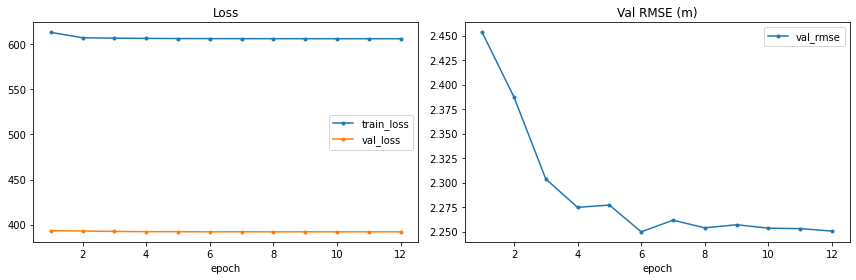

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.464638,1.181416,2.103940,3.270583,4.678919,2.339899,121130.0
site us-101,0.440060,1.154503,2.099738,3.328192,4.837417,2.371982,62135.0
zero-neighbour samples,0.549911,1.354216,2.407173,3.734873,5.284122,2.666059,3120.0
site i-80,0.489190,1.209115,2.108354,3.208797,4.505963,2.304284,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/grip_pp.json


PosixPath('/home/st_students/MTP/experiments/results/grip_pp.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
gava,LOOSE (name only): gated attention + conditional VAE,"us-101,i-80",12,210757,0.4679,1.1431,1.9574,2.9665,4.1877,2.1445,2.1282,2.5460,2.1605
fhif,LOOSE: individual / pairwise / group interaction features fused hierarchically with gates,"us-101,i-80",12,171141,0.4782,1.1477,1.9584,2.9617,4.1814,2.1455,2.1451,2.5409,2.1447
gnp,GNP: attention goal predictor + learned social-force rollout towards each goal,"us-101,i-80",12,49399,0.4886,1.1634,1.9871,3.0225,4.2939,2.1911,2.1590,2.7703,2.2232
cf_lstm,"LOOSE: cascaded LSTMs (vehicle states, then target + per-step pooled interaction)","us-101,i-80",12,175109,0.4755,1.1638,2.0026,3.0541,4.3407,2.2073,2.2001,2.5426,2.2135
cs_lstm,CS-LSTM: LSTM encoders + 13x3 convolutional social pooling (unimodal),"us-101,i-80",12,192117,0.4738,1.1644,2.0267,3.1300,4.5015,2.2593,2.2737,2.5803,2.2420
bat,"BAT-style: centrality behaviour features + polar pooling + priority attention, 9 latent manoeuvres","us-101,i-80",12,152015,0.5486,1.2622,2.1246,3.1774,4.4043,2.3034,2.3297,4.3391,2.2746
grip_pp,"GRIP++-style: distance graph + trainable graph, graph conv blocks, 3 averaged seq2seq GRUs","us-101,i-80",12,313231,0.4646,1.1814,2.1039,3.2706,4.6789,2.3399,2.3720,2.6661,2.3043


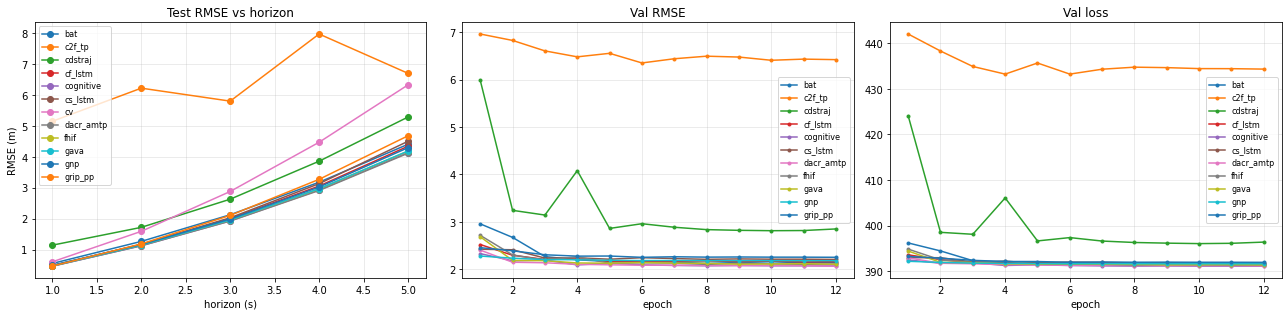

In [9]:
rmse_df, collision_df = compare()